# 5 · Cross-modal geometry and ablation

**Question.** Does refusal on **image** inputs use the same internal machinery as refusal on **text** inputs?
Measured on fixed models (no training).

**Method.** 160 matched harmful/harmless request pairs, as text and rendered as images. A legibility gate first:
the model must answer ARC shown as images at least halfway between chance and its text accuracy. The refusal
**direction** is the difference of mean final-token states between harmful and harmless requests, at the most
separable layer. **Ablation** projects a direction out of every decoder-layer output. Controls: a random
direction, and ARC after every ablation (capability). **Held-out:** directions fitted on half the pairs and
measured on the other half. *Kept* = refusal gap after ablation ÷ gap before.

In [1]:
import sys, os; sys.path.insert(0, ".")
import numpy as np, pandas as pd
from kwm import *
setup(); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
RUNS = {"refusal · 2B · seed 0": "E3-E4_refusal_crossmodal-ablation_Qwen3.5-2B_seed0.json",
        "refusal · 2B · seed 0 · held-out": "E3-E4_refusal_crossmodal-ablation_Qwen3.5-2B_seed0_heldout.json",
        "refusal · 2B · seed 1": "E3-E4_refusal_crossmodal-ablation_Qwen3.5-2B_seed1.json",
        "refusal · 0.8B · seed 0": "E3-E4_refusal_crossmodal-ablation_Qwen3.5-0.8B_seed0.json",
        "refusal · 0.8B · seed 0 · held-out": "E3-E4_refusal_crossmodal-ablation_Qwen3.5-0.8B_seed0_heldout.json",
        "values · 2B · seed 0": "E4_values_crossmodal-ablation_Qwen3.5-2B_seed0.json",
        "values · 2B · seed 0 · held-out": "E4_values_crossmodal-ablation_Qwen3.5-2B_seed0_heldout.json"}
rows = []
for name, f in RUNS.items():
    R = load("multimodal/" + f); g, b, a, L = R["geometry"], R["baseline"], R["ablation"], R["legibility"]
    cap = all(a[x]["arc_text"] >= L["arc_text"] - .05 and a[x]["arc_image"] >= L["arc_image"] - .05 for x in ("text_dir", "image_dir"))
    rows.append({"run": name, "ARC text/image": f"{L['arc_text']:.2f}/{L['arc_image']:.2f}",
                 "image ÷ text strength": round(b["image_wrap"]["gap"] / b["text_wrap"]["gap"], 2),
                 "text–image angle °": round(g["angle_deg"]["text_wrap|image_wrap"], 1),
                 "split-half ° text/image": f"{g['split_half_deg']['text_plain']:.0f}/{g['split_half_deg']['image_wrap']:.0f}",
                 "text dir removed: text kept": round(a["text_dir"]["text_plain"]["gap_retained"], 2),
                 "text dir removed: image kept": round(a["text_dir"]["image_wrap"]["gap_retained"], 2),
                 "image dir removed: text kept": round(a["image_dir"]["text_plain"]["gap_retained"], 2),
                 "image dir removed: image kept": round(a["image_dir"]["image_wrap"]["gap_retained"], 2),
                 "random: text/image kept": f"{a['random_dir']['text_plain']['gap_retained']:.2f}/{a['random_dir']['image_wrap']['gap_retained']:.2f}",
                 "capability intact": cap})
T = pd.DataFrame(rows).set_index("run"); T

,ARC text/image,image ÷ text strength,text–image angle °,split-half ° text/image,text dir removed: text kept,text dir removed: image kept,image dir removed: text kept,image dir removed: image kept,random: text/image kept,capability intact
run,,,,,,,,,,
refusal · 2B · seed 0,0.92/0.84,0.71,39.9,10/10,0.05,0.35,-0.01,0.06,0.99/1.02,True
refusal · 2B · seed 0 · held-out,0.92/0.84,0.71,39.8,15/16,0.07,0.38,-0.01,0.07,0.99/1.01,True
refusal · 2B · seed 1,0.92/0.84,0.71,40.0,9/10,0.04,0.34,-0.01,0.06,0.97/0.95,True
refusal · 0.8B · seed 0,0.89/0.74,0.34,51.2,8/15,0.20,0.33,0.34,0.10,1.02/0.99,True
refusal · 0.8B · seed 0 · held-out,0.89/0.74,0.34,49.9,17/29,0.16,0.32,0.32,0.11,1.02/0.98,True
values · 2B · seed 0,0.92/0.84,0.49,44.2,14/30,0.34,0.36,0.31,0.20,0.93/0.92,False
values · 2B · seed 0 · held-out,0.92/0.84,0.47,44.7,32/46,0.38,0.42,0.34,0.25,0.92/0.92,False


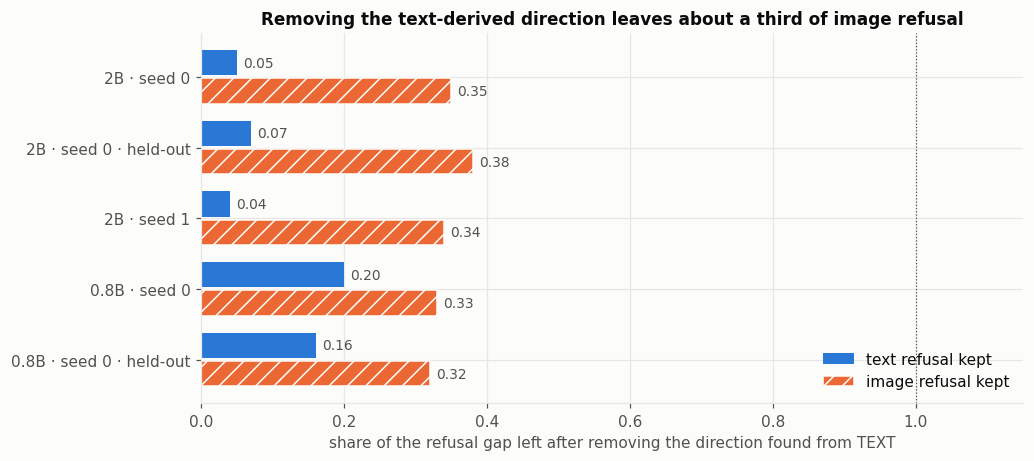

In [2]:
ref = [n for n in RUNS if n.startswith("refusal")]
y, h = np.arange(len(ref)), 0.36
tk, ik = [T.loc[n, "text dir removed: text kept"] for n in ref], [T.loc[n, "text dir removed: image kept"] for n in ref]
fig, ax = plt.subplots(figsize=(9.5, 4.3))
ax.barh(y - h / 2 - 0.02, tk, height=h, color=BLUE, label="text refusal kept")
ax.barh(y + h / 2 + 0.02, ik, height=h, color=ORANGE, hatch="//", edgecolor=SURFACE, label="image refusal kept")
for yy, v in list(zip(y - h / 2 - 0.02, tk)) + list(zip(y + h / 2 + 0.02, ik)):
    ax.annotate(f"{v:.2f}", (v, yy), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_yticks(y); ax.set_yticklabels([n.replace("refusal · ", "") for n in ref]); ax.invert_yaxis()
ax.axvline(1, color=INK2, lw=0.8, ls=":"); ax.set_xlim(0, 1.15)
ax.set_xlabel("share of the refusal gap left after removing the direction found from TEXT")
ax.legend(loc="lower right"); ax.set_title("Removing the text-derived direction leaves about a third of image refusal")
fig.tight_layout(); plt.show()

**Split test (contested values, 2B).** The picture-derived value direction is split into its part along the text direction and the part orthogonal to it ("picture-only"), and each is removed separately.

In [3]:
S = load("multimodal/E5_values_picture-only-route-split_Qwen3.5-2B_seed0.json"); d = S["decomposition"]
print(f"picture direction: {d['shared_fraction_of_v_img']:.2f} along the text direction, {d['specific_fraction_of_v_img']:.2f} orthogonal; "
      f"cosine of the picture-only part with the image-minus-text offset: {d['cos_with_modality_offset']['image_specific']:+.3f}")
pd.DataFrame([{"removed": k.replace("_", " "), "value behaviour kept, text": round(v["kept_text_plain"], 2),
               "value behaviour kept, image": round(v["kept_image_wrap"], 2), "ARC text": v["arc_text"], "ARC image": v["arc_image"]}
              for k, v in S["ablation"].items()]).set_index("removed")

picture direction: 0.75 along the text direction, 0.66 orthogonal; cosine of the picture-only part with the image-minus-text offset: +0.001


,"value behaviour kept, text","value behaviour kept, image",ARC text,ARC image
removed,,,,
image dir repro,0.31,0.20,0.77,0.69
image specific,0.89,0.65,0.92,0.82
both parts,0.26,0.20,0.76,0.71
random,0.93,0.92,0.91,0.85


## Natural images (VLSBench, 2B)
Harmful requests where the harm is in a photo (80 real, 80 generated; neutral query, no explicit category) against 160
benign COCO photos with neutral queries. The matched text version gives the dataset's image description instead of
the photo. The text-derived direction is the same as above, fitted on the standard text pairs.

,refusal gap,separability d,"kept, text dir removed","kept, natural_image dir removed","kept, random dir removed"
input,,,,,
text (standard pairs),7.24,2.87,0.05,0.66,0.99
rendered text as image,5.74,2.39,0.35,0.65,1.02
harmful photo,2.51,1.38,0.66,0.11,1.01
photo described in text,1.60,0.75,0.44,0.66,1.02


angle to the text direction: rendered image 42°, photo 78° (split-half noise 13°) | ARC after text-dir ablation 0.93/0.86 (base 0.92/0.84)


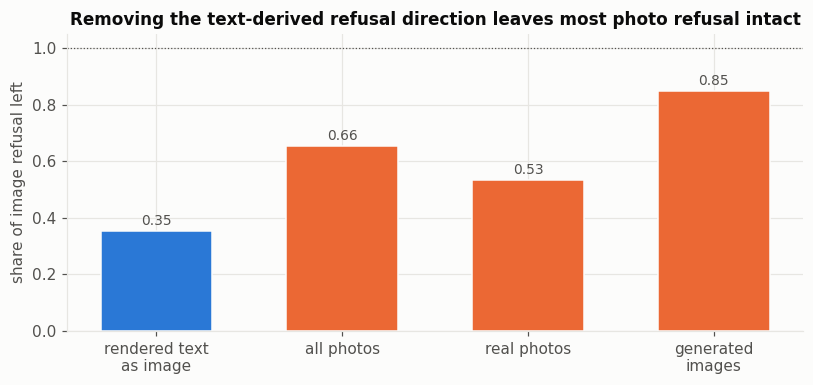

In [4]:
N = load("multimodal/E6_refusal_natural-photos-ablation_Qwen3.5-2B_seed0.json")
names = {"text_plain": "text (standard pairs)", "image_wrap": "rendered text as image", "natural_image": "harmful photo", "natural_text": "photo described in text"}
rows = [{"input": names[k], "refusal gap": round(v["gap"], 2), "separability d": round(v["d_margin"], 2),
         **{f"kept, {an.replace('_dir', '')} dir removed": round(N["ablation"][an][k]["kept"], 2) for an in ("text_dir", "natural_image_dir", "random_dir")}}
        for k, v in N["baseline"].items()]
display(pd.DataFrame(rows).set_index("input"))
g = N["geometry"]; print(f"angle to the text direction: rendered image {g['angle_deg']['text_plain|image_wrap']:.0f}°, photo {g['angle_deg']['text_plain|natural_image']:.0f}° "
      f"(split-half noise {g['split_half_deg']['natural_image']:.0f}°) | ARC after text-dir ablation {N['ablation']['text_dir']['arc_text']:.2f}/{N['ablation']['text_dir']['arc_image']:.2f} (base {N['arc']['text']:.2f}/{N['arc']['image']:.2f})")
vals = [("rendered text\nas image", N["ablation"]["text_dir"]["image_wrap"]["kept"]), ("all photos", N["ablation"]["text_dir"]["natural_image"]["kept"]),
        ("real photos", N["by_source"]["real"]["kept_text_dir"]), ("generated\nimages", N["by_source"]["generated"]["kept_text_dir"])]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar(range(len(vals)), [v for _, v in vals], color=[BLUE, ORANGE, ORANGE, ORANGE], edgecolor=SURFACE, width=0.6)
for i, (_, v) in enumerate(vals): ax.annotate(f"{v:.2f}", (i, v), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=INK2)
ax.set_xticks(range(len(vals))); ax.set_xticklabels([n for n, _ in vals]); ax.set_ylim(0, 1.05); ax.axhline(1, color=INK2, lw=0.8, ls=":")
ax.set_ylabel("share of image refusal left"); ax.set_title("Removing the text-derived refusal direction leaves most photo refusal intact")
fig.tight_layout(); plt.show()

## What this shows
1. **Image refusal is weaker and partly separate:** 71% of text strength at 2B, 34% at 0.8B; the text and image
   directions are 40° (2B) and 51° (0.8B) apart, against 8–15° of split-half noise (in-sample runs).
2. **Removing the text-derived direction leaves about a third of image refusal** — at two sizes, two seeds and on
   held-out items (held-out changes figures by at most four points). A random direction removes nothing and ARC is intact.
   At 0.8B the text direction also leaves 16–20% of *text* refusal, so refusal is less concentrated in the smaller model.
3. At 2B the image-derived direction removes text refusal completely; at 0.8B only about two thirds, so that asymmetry is 2B-specific.
4. **Values are less concentrated than refusal:** one text direction removes only ~60–65% even in text. A
   picture-only direction carries a third of image-input value behaviour and can be removed at no cost to ability;
   removing both parts costs ~15 ARC points (which is why the value rows show *capability intact = False*). In the
   held-out run (170 fitting items) the picture-derived value direction fails the reproducibility gate (split-half
   46°), so value directions need more items than refusal ones.

5. **Harmful photos run mostly off the text route.** The photo refusal direction sits 78° from the text direction, and
   removing the text direction leaves 66% of photo refusal (real photos 53%, generated 85%), against 35% for rendered
   text. Removing the photo-derived direction removes 89% of photo refusal but only a third of text refusal.
   Pre-registered prediction (≥ 30% left) passed.

*Note:* the `gates` block stored inside the two value files predates the fix that checks capability after **every**
ablation; this notebook recomputes it from the stored ARC numbers.

## Caveats and positioning
Static models only; rendered-text images; refusal read from the first token. Prior work establishes that safety
transfers poorly to images when a VLM is built (Xu et al., ICLR 2025) and that defences need both modalities
(CARE, Fu et al., CVPR 2026): these results quantify the attack side (see `docs/literature.md`).